# 04 - Evaluation and error analysis

Final model: fine-tuned PubMedBERT bi-encoder (`models/best_bi_encoder`), matching against training questions.
Covers where it fails, out-of-domain detection, choosing the answer inside an intent, and examples
exported for manual analysis. No training, runs fine on a laptop.

## 0. Setup

In [1]:
import os
import subprocess
import sys

IN_COLAB = "google.colab" in sys.modules
REPO_URL = "https://github.com/Eddydev-ALU/ML_Technique_I_Summative_sti-qa-assistant.git"
if IN_COLAB:
    if not os.path.exists("/content/repo"):
        subprocess.run(["git", "clone", REPO_URL, "/content/repo"], check=True)
    os.chdir("/content/repo")
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "sentence-transformers==6.1.0",
                    "transformers==5.20.0", "rank_bm25==0.2.2", "openpyxl==3.1.5"], check=True)
    subprocess.run([sys.executable, "-m", "src.download_data"], check=True)
    subprocess.run([sys.executable, "-m", "src.data_prep"], check=True)
elif os.path.basename(os.getcwd()) == "notebooks":
    os.chdir("..")
sys.path.insert(0, os.getcwd())
print("Working directory:", os.getcwd())

Working directory: /Users/apple/Documents/ML_Technique_I_Summative_frontline-health-qa


In [2]:
import json

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from src.answer_selection import AnswerSelector
from src.baselines import TfidfLogRegBaseline
from src.data_prep import load_prepared
from src.evaluate import (choose_threshold, confidence, ood_metrics, per_category_accuracy,
                          ranking_metrics, threshold_for_coverage, true_ranks)
from src.models import EmbeddingRetriever

SEED = 42
MODEL_PATH = "models/best_bi_encoder"
OUT_DIR = "results/error_analysis"
os.makedirs(OUT_DIR, exist_ok=True)
os.makedirs("results/figures", exist_ok=True)
pd.set_option("display.max_colwidth", 110)
pd.set_option("display.width", 200)

W1016 17:03:52.927000 74333 .venv/lib/python3.12/site-packages/torch/distributed/elastic/multiprocessing/redirects.py:35] NOTE: Redirects are currently not supported in MacOs.


## 1. Load data and the final model, score every set

In [3]:
questions, answer_bank = load_prepared()
train = questions[questions["split"] == "train"].reset_index(drop=True)
val = questions[questions["split"] == "val"].reset_index(drop=True)
test = questions[questions["split"] == "test"].reset_index(drop=True)
held_out = questions[questions["split"] == "held_out"].reset_index(drop=True)
off_topic = pd.read_csv("evaluation/off_topic_questions.csv")  # AI-written, test only

model = EmbeddingRetriever(MODEL_PATH, mode="q2q").fit(train["question"], train["intent_id"], answer_bank)
intents = np.array(model.intents)
index = {intent: j for j, intent in enumerate(intents)}

scores = {name: model.score(data["question"].tolist())
          for name, data in [("val", val), ("test", test), ("held_out", held_out), ("off_topic", off_topic)]}
print({name: s.shape for name, s in scores.items()})

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

{'val': (311, 98), 'test': (333, 98), 'held_out': (381, 98), 'off_topic': (60, 98)}


In [4]:
test_true = test["intent_id"].map(index).to_numpy()
test_metrics = ranking_metrics(scores["test"], test_true)
print({k: round(v, 3) if isinstance(v, float) else v for k, v in test_metrics.items()})

{'n': 333, 'accuracy@1': 0.952, 'recall@3': 0.988, 'recall@5': 0.988, 'mrr': 0.968, 'macro_f1': 0.835}


## 2. Where does the model fail? (test set)
`nearest_train_question` is the question the model actually matched, it explains most errors.

In [5]:
# the training question each test question was matched to
test_vectors = model.encode(test["question"])
sims_to_train = test_vectors @ model.index_vectors.T
nearest = sims_to_train.argmax(axis=1)

pred = test[["question_id", "category", "question", "source", "intent_id"]].rename(columns={"intent_id": "true_intent"})
pred["predicted_intent"] = intents[scores["test"].argmax(axis=1)]
pred["confidence"] = confidence(scores["test"]).round(3)
pred["margin"] = confidence(scores["test"], "margin").round(3)
pred["rank_of_true"] = true_ranks(scores["test"], test_true)
pred["correct"] = pred["predicted_intent"] == pred["true_intent"]
pred["same_category"] = pred["predicted_intent"].str.split("::").str[0] == pred["category"]
pred["n_words"] = pred["question"].str.split().str.len()
pred["nearest_train_question"] = train["question"].to_numpy()[nearest]
pred["nearest_train_intent"] = train["intent_id"].to_numpy()[nearest]
train_size = train["intent_id"].value_counts()
pred["true_intent_train_questions"] = pred["true_intent"].map(train_size)

print(f"Test accuracy@1: {pred['correct'].mean():.3f}  ({(~pred['correct']).sum()} errors out of {len(pred)})")

Test accuracy@1: 0.952  (16 errors out of 333)


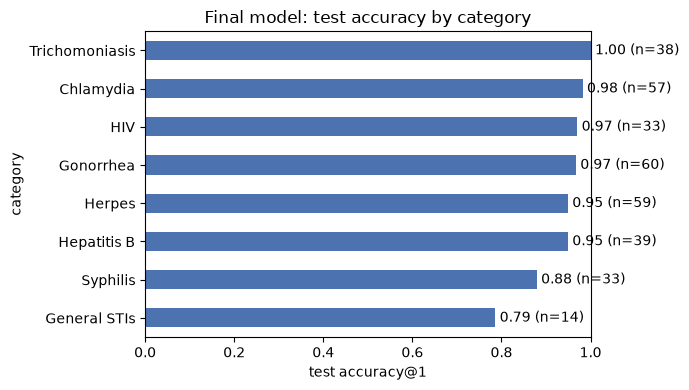

,n,accuracy
category,,
Chlamydia,57,0.982
General STIs,14,0.786
Gonorrhea,60,0.967
HIV,33,0.970
Hepatitis B,39,0.949
Herpes,59,0.949
Syphilis,33,0.879
Trichomoniasis,38,1.000


In [6]:
# per category
per_cat = per_category_accuracy(scores["test"], test_true, test["category"])
per_cat.to_csv("results/final_model_per_category.csv")
ax = per_cat["accuracy"].sort_values().plot.barh(figsize=(7, 4), color="#4C72B0", xlim=(0, 1))
for i, (acc, n) in enumerate(per_cat.sort_values("accuracy")[["accuracy", "n"]].to_numpy()):
    ax.text(acc + 0.01, i, f"{acc:.2f} (n={int(n)})", va="center")
ax.set_xlabel("test accuracy@1"); ax.set_title("Final model: test accuracy by category")
plt.tight_layout(); plt.savefig("results/figures/final_model_per_category.png", dpi=150); plt.show()
per_cat

In [7]:
# by source, length and training size
pred["length_bucket"] = pd.cut(pred["n_words"], bins=[0, 4, 8, 12, 200], labels=["1-4", "5-8", "9-12", "13+"])
by_source = pred.groupby("source")["correct"].agg(n="size", accuracy="mean").round(3)
by_length = pred.groupby("length_bucket", observed=True)["correct"].agg(n="size", accuracy="mean").round(3)
by_train_size = pred.groupby(pd.cut(pred["true_intent_train_questions"], [0, 5, 15, 30, 1000],
                                    labels=["1-5", "6-15", "16-30", "31+"]), observed=True)["correct"].agg(n="size", accuracy="mean").round(3)
by_train_size.index.name = "training questions of true intent"
display(by_source, by_length, by_train_size)

,n,accuracy
source,,
another_way,309,0.968
crowdsourced,24,0.750


,n,accuracy
length_bucket,,
1-4,72,0.958
5-8,200,0.960
9-12,46,0.935
13+,15,0.867


,n,accuracy
training questions of true intent,,
1-5,25,0.720
6-15,46,0.826
16-30,143,1.000
31+,119,0.992


In [8]:
# right disease, wrong intent?
errors = pred[~pred["correct"]]
print(f"{len(errors)} errors: {errors['same_category'].sum()} in the correct category, "
      f"{(~errors['same_category']).sum()} in a different category")
print(f"Correct intent ranked 2nd: {(errors['rank_of_true'] == 2).sum()} of {len(errors)} errors")
print("\nMost common confusions (true -> predicted):")
errors.groupby(["true_intent", "predicted_intent"]).size().sort_values(ascending=False).head(10)

16 errors: 14 in the correct category, 2 in a different category
Correct intent ranked 2nd: 7 of 16 errors

Most common confusions (true -> predicted):


true_intent                                 predicted_intent                         
Chlamydia::Transmission_spread_chlamydia    Chlamydia::complications_chlamydia           1
General STIs::complications_stis            Gonorrhea::symptoms_Signs_gonorrhea          1
General STIs::education_stis                HIV::safe_sex_practices_hiv                  1
General STIs::misconception_stis            General STIs::prevention_stis                1
Gonorrhea::prevention_gonorrhea_No          Gonorrhea::prevention_gonorrhea_Yes          1
Gonorrhea::safe_sex_practices_gonorrhea     Gonorrhea::Treatment/Medication_gonorrhea    1
HIV::education_hiv                          HIV::Treatment/Medication_hiv                1
Hepatitis B::Myths_misconception_hepatitis  Hepatitis B::education_hepatitis             1
Hepatitis B::education_hepatitis            Hepatitis B::medication_hepatitis            1
Herpes::Myths_misconception_infections      Herpes::complications_infections             1
dtyp

In [9]:
# all test errors
errors.sort_values("confidence", ascending=False)[
    ["question", "true_intent", "predicted_intent", "confidence", "rank_of_true", "nearest_train_question"]]

,question,true_intent,predicted_intent,confidence,rank_of_true,nearest_train_question
315,Is there vaccination against Syphilis?,Syphilis::prevention_syphilis,Syphilis::vaccination_syphilis,0.967,3,Is there a vaccine for Syphilis?
112,Can Hepatitis B be treated like HIV?,Hepatitis B::education_hepatitis,Hepatitis B::medication_hepatitis,0.953,3,How is Hepatitis B treated?
327,"If I am treated for Syphilis, when can I have sex again?",Syphilis::safe_sex_practices_syphilis,Syphilis::Treatment/Medication_syphilis,0.934,3,Can I have sex while on treatment for Syphilis?
63,"While I am on treatment for Gonorrhea, do I need to use a condom?",Gonorrhea::safe_sex_practices_gonorrhea,Gonorrhea::Treatment/Medication_gonorrhea,0.884,2,Can I have sex while on treatment for Gonorrhea?
109,Is Hepatitis B HIV?,Hepatitis B::Myths_misconception_hepatitis,Hepatitis B::education_hepatitis,0.878,2,Difference between Hepatitis B and HIV
43,Can circumcision protect me from Gonorrhea?,Gonorrhea::prevention_gonorrhea_No,Gonorrhea::prevention_gonorrhea_Yes,0.858,12,Can having one sexual partner protect me from getting gonorrhea?
203,Can someone infect themselves with Herpes from the mouth to the genitals if they accidently touch themselves?,Herpes::complications_infections,Herpes::Transmission_spread_infections,0.845,3,"If I share a swimming pool with someone with Genital Herpes, can I get Genital Herpes?"
204,Does Herpes cause Cervical Cancer?,Herpes::education_infections,Herpes::complications_infections,0.839,10,What other diseases can Herpes cause?
197,Can Herpes affect libido?,Herpes::Myths_misconception_infections,Herpes::complications_infections,0.824,2,How does Herpes affect a pregnant mother and her baby?
272,Can chlamydia affect my child?,Chlamydia::Transmission_spread_chlamydia,Chlamydia::complications_chlamydia,0.812,2,What other diseases can chlamydia cause?


## 3. Out-of-domain detection
Out-of-domain examples:
- held-out intents: real STI questions about 11 topics the model never saw (on-topic but unknown)
- 60 off-topic questions (written with an AI assistant, test only, see `evaluation/README.md`)

The threshold is chosen on a tuning half and reported on a separate test half:
val / test for in-domain, held-out intents split by intent, off-topic split per type.

In [10]:
rng = np.random.default_rng(SEED)
held_intents = sorted(held_out["intent_id"].unique())
held_intents = list(rng.permutation(held_intents))
tune_intents = held_intents[: len(held_intents) // 2]
print("Held-out intents for TUNING:", *tune_intents, sep="\n  ")
print("Held-out intents for TESTING:", *held_intents[len(held_intents) // 2:], sep="\n  ")

held_tune = held_out["intent_id"].isin(tune_intents).to_numpy()
off_tune = np.zeros(len(off_topic), dtype=bool)
for _, rows in off_topic.groupby("type").groups.items():
    rows = rng.permutation(np.array(rows))
    off_tune[rows[: len(rows) // 2]] = True
print(f"\nTuning: {len(val)} in-domain, {held_tune.sum()} held-out, {off_tune.sum()} off-topic")
print(f"Test  : {len(test)} in-domain, {(~held_tune).sum()} held-out, {(~off_tune).sum()} off-topic")

Held-out intents for TUNING:
  Herpes::definition_infections
  Herpes::prevention_infections
  Chlamydia::prevention_chlamydia
  Trichomoniasis::spread_trichomoniasis
  HIV::definition_hiv
Held-out intents for TESTING:
  Hepatitis B::types_hepatitis
  General STIs::signs_symptoms_stis
  Hepatitis B::definition_hepatitis
  Trichomoniasis::origin_trichomoniasis
  Chlamydia::safe_sex_practices_chlamydia
  Syphilis::origin_syphilis

Tuning: 311 in-domain, 221 held-out, 30 off-topic
Test  : 333 in-domain, 160 held-out, 30 off-topic


In [11]:
# TF-IDF + LR for comparison: is its max probability a useful confidence?
tfidf = TfidfLogRegBaseline(analyzer="char_wb", ngram_range=(2, 5), C=100.0).fit(train["question"], train["intent_id"])
tfidf_scores = {name: tfidf.score(data["question"].tolist())
                for name, data in [("val", val), ("test", test), ("held_out", held_out), ("off_topic", off_topic)]}

detectors = {
    "PubMedBERT top-1 cosine": (scores, "top1"),
    "PubMedBERT margin (top1 - top2)": (scores, "margin"),
    "TF-IDF+LR max probability": (tfidf_scores, "top1"),
}

rows, chosen = [], {}
for name, (sc, kind) in detectors.items():
    conf = {k: confidence(v, kind) for k, v in sc.items()}
    tune_in = conf["val"]
    tune_out = np.concatenate([conf["held_out"][held_tune], conf["off_topic"][off_tune]])
    test_in = conf["test"]
    test_out = np.concatenate([conf["held_out"][~held_tune], conf["off_topic"][~off_tune]])

    for rule, t in [("best F1 on tuning half", choose_threshold(tune_in, tune_out)),
                    ("answer 95% of val", threshold_for_coverage(tune_in, 0.95))]:
        m = ood_metrics(test_in, test_out, t)
        rows.append({"confidence": name, "threshold rule": rule, **{k: round(v, 3) for k, v in m.items()}})
    chosen[name] = (conf, choose_threshold(tune_in, tune_out))

ood_table = pd.DataFrame(rows)
ood_table.to_csv("results/ood_results.csv", index=False)
ood_table

,confidence,threshold rule,threshold,ood_precision,ood_recall,ood_f1,in_domain_answered
0,PubMedBERT top-1 cosine,best F1 on tuning half,0.854,0.890,0.984,0.935,0.931
1,PubMedBERT top-1 cosine,answer 95% of val,0.800,0.947,0.942,0.945,0.970
2,PubMedBERT margin (top1 - top2),best F1 on tuning half,0.153,0.747,0.932,0.829,0.820
3,PubMedBERT margin (top1 - top2),answer 95% of val,0.025,0.839,0.247,0.382,0.973
4,TF-IDF+LR max probability,best F1 on tuning half,0.638,0.639,0.942,0.762,0.697
5,TF-IDF+LR max probability,answer 95% of val,0.232,0.747,0.295,0.423,0.943


Numbers are on the test half. `in_domain_answered` = share of real test questions that still get an answer.

In [12]:
# pick the confidence measure on the tuning half
def tuning_f1(name):
    conf, t = chosen[name]
    tune_out = np.concatenate([conf["held_out"][held_tune], conf["off_topic"][off_tune]])
    return ood_metrics(conf["val"], tune_out, t)["ood_f1"]

tuning = {name: round(tuning_f1(name), 3) for name in chosen if name.startswith("PubMedBERT")}
print("Tuning-half OOD F1:", tuning)
APP_CONFIDENCE = max(tuning, key=tuning.get)
conf, THRESHOLD = chosen[APP_CONFIDENCE]
print(f"Chosen for the app: {APP_CONFIDENCE}, threshold = {THRESHOLD:.3f}")

Tuning-half OOD F1: {'PubMedBERT top-1 cosine': 0.947, 'PubMedBERT margin (top1 - top2)': 0.879}
Chosen for the app: PubMedBERT top-1 cosine, threshold = 0.854


In [13]:
# test half, per kind of out-of-domain question
breakdown = []
held_test = ~held_tune
breakdown.append({"group": "held-out intents (unseen STI topics)", "n": int(held_test.sum()),
                  "refused": float((conf["held_out"][held_test] < THRESHOLD).mean())})
for kind in ["unrelated", "health_not_sti", "near_domain"]:
    mask = (~off_tune) & (off_topic["type"] == kind).to_numpy()
    breakdown.append({"group": f"off-topic: {kind}", "n": int(mask.sum()),
                      "refused": float((conf["off_topic"][mask] < THRESHOLD).mean())})
breakdown.append({"group": "in-domain test questions (should be ANSWERED)", "n": len(test),
                  "refused": float((conf["test"] < THRESHOLD).mean())})
breakdown = pd.DataFrame(breakdown).round(3)
breakdown.to_csv("results/ood_breakdown.csv", index=False)
breakdown

,group,n,refused
0,held-out intents (unseen STI topics),160,0.981
1,off-topic: unrelated,10,1.000
2,off-topic: health_not_sti,10,1.000
3,off-topic: near_domain,10,1.000
4,in-domain test questions (should be ANSWERED),333,0.069


In [14]:
# what happens to real test questions
answered = conf["test"] >= THRESHOLD
outcome = pd.Series(np.select([answered & pred["correct"], answered & ~pred["correct"], ~answered & ~pred["correct"]],
                              ["answered correctly", "answered WRONGLY", "refused (would have been wrong)"],
                              "refused (would have been right)")).value_counts()
print(outcome.to_string())
print(f"\nAccuracy on the questions the app does answer: {pred['correct'][answered].mean():.3f}")

answered correctly                 304
refused (would have been right)     13
refused (would have been wrong)     10
answered WRONGLY                     6

Accuracy on the questions the app does answer: 0.981


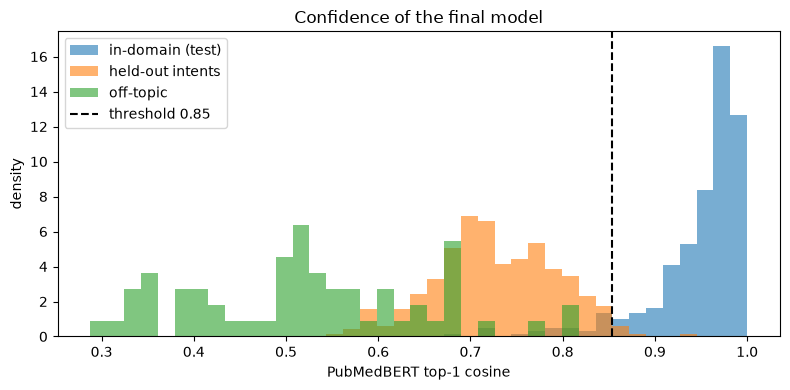

In [15]:
# confidence distributions
fig, ax = plt.subplots(figsize=(8, 4))
bins = np.linspace(min(c.min() for c in conf.values()), 1, 40)
ax.hist(conf["test"], bins=bins, alpha=0.6, label="in-domain (test)", density=True)
ax.hist(conf["held_out"], bins=bins, alpha=0.6, label="held-out intents", density=True)
ax.hist(conf["off_topic"], bins=bins, alpha=0.6, label="off-topic", density=True)
ax.axvline(THRESHOLD, color="black", linestyle="--", label=f"threshold {THRESHOLD:.2f}")
ax.set_xlabel(APP_CONFIDENCE); ax.set_ylabel("density"); ax.legend()
ax.set_title("Confidence of the final model")
plt.tight_layout(); plt.savefig("results/figures/ood_confidence.png", dpi=150); plt.show()

In [16]:
# threshold for the app
with open("results/ood_threshold.json", "w") as f:
    json.dump({"confidence": APP_CONFIDENCE, "threshold": THRESHOLD, "model": MODEL_PATH,
               "note": "chosen on the tuning half (val + half of held-out intents + half of off-topic)"}, f, indent=2)
print(open("results/ood_threshold.json").read())

{
  "confidence": "PubMedBERT top-1 cosine",
  "threshold": 0.8537175059318542,
  "model": "models/best_bi_encoder",
  "note": "chosen on the tuning half (val + half of held-out intents + half of off-topic)"
}


### 3b. "Not sure" zone
Real questions with typos and slang score lower than the dataset's paraphrases, so one threshold
refuses too many of them. The app uses two: answer above the first, "did you mean...?" between the two,
refuse below the second. The lower one is the 90th percentile of the tuning off-topic confidences.

In [17]:
LOW_THRESHOLD = float(np.percentile(conf["off_topic"][off_tune], 90))
print(f"upper threshold {THRESHOLD:.3f} | lower threshold {LOW_THRESHOLD:.3f}")

def zones(c):
    return {"answer": float((c >= THRESHOLD).mean()),
            "not sure": float(((c >= LOW_THRESHOLD) & (c < THRESHOLD)).mean()),
            "refuse": float((c < LOW_THRESHOLD).mean())}

zone_rows = []
for name, c in [("in-domain test (all)", conf["test"]),
                ("in-domain test, model correct", conf["test"][pred["correct"].to_numpy()]),
                ("in-domain test, model WRONG", conf["test"][~pred["correct"].to_numpy()]),
                ("in-domain test, crowdsourced questions", conf["test"][(pred["source"] == "crowdsourced").to_numpy()]),
                ("held-out intents (test half)", conf["held_out"][~held_tune]),
                ("off-topic (test half)", conf["off_topic"][~off_tune])]:
    zone_rows.append({"group": name, "n": len(c), **{k: round(v, 3) for k, v in zones(c).items()}})
zone_table = pd.DataFrame(zone_rows)
zone_table.to_csv("results/ood_three_zones.csv", index=False)
zone_table

upper threshold 0.854 | lower threshold 0.728


,group,n,answer,not sure,refuse
0,in-domain test (all),333,0.931,0.057,0.012
1,"in-domain test, model correct",317,0.959,0.035,0.006
2,"in-domain test, model WRONG",16,0.375,0.500,0.125
3,"in-domain test, crowdsourced questions",24,0.708,0.208,0.083
4,held-out intents (test half),160,0.019,0.381,0.600
5,off-topic (test half),30,0.000,0.000,1.000


In [18]:
with open("results/ood_threshold.json") as f:
    info = json.load(f)
info.update({"low_threshold": LOW_THRESHOLD,
             "low_threshold_rule": "90th percentile of the tuning-half off-topic confidences"})
with open("results/ood_threshold.json", "w") as f:
    json.dump(info, f, indent=2)
print(open("results/ood_threshold.json").read())

{
  "confidence": "PubMedBERT top-1 cosine",
  "threshold": 0.8537175059318542,
  "model": "models/best_bi_encoder",
  "note": "chosen on the tuning half (val + half of held-out intents + half of off-topic)",
  "low_threshold": 0.7278328299522401,
  "low_threshold_rule": "90th percentile of the tuning-half off-topic confidences"
}


## 4. Choosing one answer inside a multi-answer intent
Val/test questions that sit on the same Excel row as an answer, in intents with more than one answer.
The true intent is given, so this only measures the answer choice. The row alignment in the file isn't
always right, so treat the numbers as an estimate.

In [19]:
answers_per_intent = answer_bank.groupby("intent_id").size()
eval_set = pd.concat([val, test])
eval_set = eval_set[eval_set["row_answer_id"].notna() & eval_set["intent_id"].map(answers_per_intent).gt(1)].reset_index(drop=True)
print("Questions in the step-2 evaluation set:", len(eval_set))
k = eval_set["intent_id"].map(answers_per_intent)
print(f"Average number of answers to choose from: {k.mean():.1f}")

def step2_accuracy(chosen_ids):
    return float(np.mean(np.array(chosen_ids) == eval_set["row_answer_id"].to_numpy()))

step2 = {"random choice (expected)": float((1 / k).mean())}
selector = AnswerSelector(model.encode, answer_bank)
step2["always the first answer"] = step2_accuracy(selector.select(eval_set["question"], eval_set["intent_id"], method="first"))
step2["answer-text matching, fine-tuned PubMedBERT (step-1 model)"] = step2_accuracy(
    selector.select(eval_set["question"], eval_set["intent_id"], method="semantic"))
# encoders that weren't fine-tuned
for name, path in [("frozen PubMedBERT", "NeuML/pubmedbert-base-embeddings"),
                   ("frozen MiniLM", "sentence-transformers/all-MiniLM-L6-v2")]:
    encoder = EmbeddingRetriever(path, mode="q2q")
    step2[f"answer-text matching, {name}"] = step2_accuracy(
        AnswerSelector(encoder.encode, answer_bank).select(eval_set["question"], eval_set["intent_id"], method="semantic"))
step2 = pd.Series(step2, name="accuracy").round(3)
step2.to_csv("results/answer_selection.csv")
step2

Questions in the step-2 evaluation set: 99
Average number of answers to choose from: 7.6


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

random choice (expected)                                      0.192
always the first answer                                       0.202
answer-text matching, fine-tuned PubMedBERT (step-1 model)    0.465
answer-text matching, frozen PubMedBERT                       0.505
answer-text matching, frozen MiniLM                           0.556
Name: accuracy, dtype: float64

The fine-tuned model is worst here: training pulled all questions of an intent together, so it no
longer sees the differences inside an intent. That's why the app uses fine-tuned PubMedBERT for the
intent and frozen MiniLM for the answer.

## 5. Examples for manual error analysis
`test_examples.csv` (all test errors + some confident and unsure correct ones) and `ood_examples.csv`.
The `error_type` and `notes` columns are for my manual analysis.

In [20]:
correct = pred[pred["correct"]].sort_values("confidence")
examples = pd.concat([
    errors.assign(example_kind="error"),
    correct.tail(15).assign(example_kind="success (most confident)"),
    correct.head(10).assign(example_kind="success (least confident)"),
])
examples["would_answer"] = examples["confidence"] >= THRESHOLD if APP_CONFIDENCE.endswith("cosine") else examples["margin"] >= THRESHOLD
examples["error_type"], examples["notes"] = "", ""
cols = ["example_kind", "question", "true_intent", "predicted_intent", "confidence", "margin", "rank_of_true",
        "would_answer", "nearest_train_question", "nearest_train_intent", "n_words", "source", "error_type", "notes"]
examples[cols].to_csv(f"{OUT_DIR}/test_examples.csv", index=False)

ood_examples = pd.concat([
    off_topic.assign(kind=lambda d: "off-topic: " + d["type"], true_intent="(none)"),
    held_out.assign(kind="held-out intent", true_intent=held_out["intent_id"])[["question", "kind", "true_intent"]],
], ignore_index=True)
all_ood_scores = np.vstack([scores["off_topic"], scores["held_out"]])
all_ood_conf = np.concatenate([conf["off_topic"], conf["held_out"]])
ood_examples["predicted_intent"] = intents[all_ood_scores.argmax(axis=1)]
ood_examples["confidence"] = all_ood_conf.round(3)
ood_examples["refused"] = all_ood_conf < THRESHOLD
ood_examples["half"] = np.concatenate([np.where(off_tune, "tuning", "test"), np.where(held_tune, "tuning", "test")])
ood_examples["error_type"], ood_examples["notes"] = "", ""
held_top = ood_examples[ood_examples["kind"] == "held-out intent"].nlargest(20, "confidence")
ood_export = pd.concat([ood_examples[ood_examples["kind"] != "held-out intent"], held_top])
ood_export.drop(columns="type").to_csv(f"{OUT_DIR}/ood_examples.csv", index=False)
print(len(examples), "test examples and", len(ood_export), "OOD examples exported to", OUT_DIR)

41 test examples and 80 OOD examples exported to results/error_analysis


In [21]:
# off-topic questions that would get an answer
ood_examples[(ood_examples["kind"] != "held-out intent") & ~ood_examples["refused"]][
    ["question", "kind", "predicted_intent", "confidence", "half"]]

,question,kind,predicted_intent,confidence,half


In [22]:
# unseen STI topics with high confidence
held_top[["question", "true_intent", "predicted_intent", "confidence", "refused"]].head(10)

,question,true_intent,predicted_intent,confidence,refused
417,"If I am treated for chlamydia, when can I have sex again?",Chlamydia::safe_sex_practices_chlamydia,Chlamydia::Treatment_medication_chlamydia,0.927,False
416,"While I am on treatment for chlamydia, do I need to use a condom?",Chlamydia::safe_sex_practices_chlamydia,Chlamydia::Treatment_medication_chlamydia,0.881,False
188,Herpes Simplex Virus?Herpes Simplex Virus?,Herpes::definition_infections,Herpes::types_herpes_simplex_virus,0.864,False
332,What is the brief history of Trich?,Trichomoniasis::origin_trichomoniasis,Trichomoniasis::definition_trichomoniasis,0.861,False
285,"As a man, how can I protect myself from getting Genital Herpes?",Herpes::prevention_infections,Herpes::safe_sex_practices_infections,0.857,False
228,How can I protect Genital Herpes from myself?,Herpes::prevention_infections,Herpes::safe_sex_practices_infections,0.855,False
215,What are Herpes?,Herpes::definition_infections,Herpes::types_herpes_simplex_virus,0.852,True
281,"I am pregnant, if I have Genital Herpes, how can I protect my baby from getting it?",Herpes::prevention_infections,Herpes::safe_sex_practices_infections,0.852,True
284,"As a woman, how can I protect myself from getting Genital Herpes?",Herpes::prevention_infections,Herpes::safe_sex_practices_infections,0.850,True
213,Genital Herpes?,Herpes::definition_infections,Herpes::types_herpes_simplex_virus,0.844,True


## 6. End-to-end examples

In [23]:
def show(question):
    s = model.score([question])
    c = confidence(s, "top1" if APP_CONFIDENCE.endswith("cosine") else "margin")[0]
    intent = intents[s.argmax()]
    print(f"Q: {question}")
    if c < THRESHOLD:
        print(f"   -> I don't know (confidence {c:.3f} < {THRESHOLD:.3f})\n")
        return
    answer_id = selector.select([question], [intent])[0]
    answer = answer_bank.loc[answer_bank["answer_id"] == answer_id, "simple_answer"].iloc[0]
    print(f"   -> intent {intent} (confidence {c:.3f})\n   -> {answer[:300]}\n")

for q in list(test.sample(3, random_state=SEED)["question"]) + list(off_topic.sample(3, random_state=SEED)["question"]):
    show(q)

Q: Group Gonorrhea?
   -> intent Gonorrhea::types_gonorrhea (confidence 0.946)
   -> Gonorrhea is classified according to what part of the body is affected (urogenital, extragenital and disseminated gonorrhea) or responsiveness to treatment (regular gonorrhea or multidrug resistant/super gonorrhea).

Q: I have genital ulcers, does it mean I have Syphilis?
   -> intent Syphilis::signs_symptoms_syphilis (confidence 0.957)
   -> Syphilis causes ulcers or sores during the earliest stages of the disease, that is the priamry and secondary stage. The sores can be in any part of the body but common areas are the genitals, anus, mouth, feet and palms. However, not all sores in such ares indicate syphilis. Discuss with your doctor

Q: Does being HIV positive increase my chances of Gonorrhea?
   -> intent Gonorrhea::education_gonorrhea (confidence 0.950)
   -> Having untreated gonorrhea may also increase your chances of getting or transmitting HIV

Q: How do I plant maize so that it grows well?
 

Q: Is it safe to eat eggs every day?
   -> I don't know (confidence 0.511 < 0.854)



## 7. Observations
- 16 errors on 333 test questions, 14 of them in the right disease but a neighbouring intent, often
  overlapping intent definitions (vaccination vs prevention, treatment vs safe sex).
- Intents with 1-5 training questions get 72%, intents with 16+ get about 100%.
- Original crowdsourced questions score 75% vs 96.8% for the paraphrases, real questions are harder.
- Top-1 cosine works better as a confidence than the margin or the TF-IDF probability.
- Unseen STI topics are refused 98% of the time, all off-topic test questions are refused.
- Answer choice: frozen MiniLM 0.556, fine-tuned PubMedBERT 0.465, first answer 0.202.